<a href="https://colab.research.google.com/github/CHIJUNGLEE/run/blob/main/movie_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MovieLens 比較実験ノートブック — ベースライン vs 提案三択方策（Exploit / Explore / No-Op）

このノートブック 1 つで、コードの展開 → 実験 → 集計 → 可視化まで完結します（Jupyter / Google Colab どちらでも動作）。

**構成**
1. 準備（依存ライブラリ）
2. ソースコードの展開（`%%writefile` で `movierec/` パッケージを作成）
3. データ読み込みの確認
4. スモーク実験（ベースライン 5 本 + 三択 P4）
5. P0〜P5 パラメータスイープ
6. 結果の集計と可視化
7. OPE 推定値（IPS / SNIPS）

> 注: 標準ライブラリの `code` モジュールと名前が衝突するため、ノートブック内ではパッケージ名を `movierec` にしています（中身は `movie-experiment/code/` と同一）。
> 実 MovieLens-100k が無い場合は、同じ尺度（943 ユーザ × 1,682 アイテム × 19 ジャンル）の合成データで動きます。

## 1. 準備

In [ ]:
# 依存は numpy と matplotlib のみ（Colab では導入済み）
# !pip install -q numpy matplotlib
import numpy, matplotlib
print('numpy', numpy.__version__, '/ matplotlib', matplotlib.__version__)

numpy 2.1.3 / matplotlib 3.10.0


## 2. ソースコードの展開
各セルを実行すると `movierec/` 配下にモジュールが書き出されます。

In [ ]:
import os
os.makedirs('movierec', exist_ok=True)

### `__init__.py` — パッケージ定義

In [ ]:
%%writefile movierec/__init__.py
"""MovieLens-100k-based comparison of baselines and the proposed 3-action policy.

Modules
-------
- ``data``: loader with synthetic fallback
- ``metrics``: Recall@K, Serendipity, action-mix, etc.
- ``baselines``: Random, Popularity, MF + ε-greedy, LinUCB, REINFORCE-Exploit
- ``proposed``: 3-action policy (Exploit / Explore / No-Op) with tunable δ and a
  OPE-style offline evaluator.
- ``run_experiment``: experiment driver
- ``visualize``: matplotlib charts + CSV summary
"""

__all__ = [
    "data",
    "metrics",
    "baselines",
    "proposed",
    "run_experiment",
    "visualize",
]


Writing movierec/__init__.py


### `data.py` — データ読み込み（実データ + 合成フォールバック）

In [ ]:
%%writefile movierec/data.py
"""データ読み込みモジュール。

このファイルの役割は「推薦実験で扱うデータのかたち」を 1 か所に決めておくこと。
大きく 2 つの動きをします:

1. 本物の MovieLens-100k が見つかればそれを読む (``_try_load_movielens``)
2. 見つからなければ 943 ユーザ × 1,682 アイテム × 19 ジャンルの合成データを
   作る (``make_synthetic``)。中間発表の Slide 12 と同じ数字に揃えています

呼び出し側 (``run_experiment.py`` など) は ``load_dataset()`` だけ知っていれば
よく、``Dataset`` を受け取ったら train/test と ``user_genre_pref`` などの
メタが取り出せます。

依存: numpy だけ。``zip`` を読むために標準ライブラリの ``zipfile`` を使います。
"""
from __future__ import annotations

import os
import random
from dataclasses import dataclass
from typing import Dict, Iterable, List

import numpy as np


# ──────────────────────────────────────────────────────────────────────
# データ構造
# ──────────────────────────────────────────────────────────────────────

@dataclass(frozen=True)
class Interaction:
    """1 件の評価履歴。イミュータブル (frozen) にしてあって、train/test
    どちらでも同じ型で扱えます。

    Attributes:
        user:      ユーザ ID （ロード後に 0 始まりの密インデックスへ再マップ）
        item:      アイテム ID （同上）
        rating:    元データの評価値（MovieLens-100k は 1〜5）
        timestamp: 時系列分割に使うタイムスタンプ
        genre:     アイテムの主ジャンル（0..n_genres-1）
    """
    user: int
    item: int
    rating: float
    timestamp: int
    genre: int


@dataclass
class Dataset:
    """実験で使うデータ全体。下流はとりあえずこの型だけ知っていれば OK。

    Attributes:
        n_users:         ユーザ数
        n_items:         アイテム数
        n_genres:        ジャンル数（19 に合わせている）
        user_genre_pref: (n_users, n_genres) のソフト選好。各行は合計 1
        item_genre:      (n_items,) 主ジャンル
        item_popularity: (n_items,) 学習用集合内での出現回数
        train:           学習用イベント列（時系列順）
        test:            評価用イベント列（時系列順）
        name:            表示用ラベル ("MovieLens-100k" か "Synthetic-100k_...")
    """
    n_users: int
    n_items: int
    n_genres: int
    user_genre_pref: np.ndarray
    item_genre: np.ndarray
    item_popularity: np.ndarray
    train: List[Interaction]
    test: List[Interaction]
    name: str

    @property
    def n_train(self) -> int:
        """学習イベントの件数。"""
        return len(self.train)

    @property
    def n_test(self) -> int:
        """評価イベントの件数。"""
        return len(self.test)


# ──────────────────────────────────────────────────────────────────────
# 本物の MovieLens-100k を読む
# ──────────────────────────────────────────────────────────────────────

def _try_load_movielens(root: str) -> Dataset | None:
    """MovieLens-100k の ``u.data`` を探して読む。

    次の順に探します:
        1. ``{root}/u.data``（フォルダあるケース）
        2. ``{root}/ml-100k/u.data``
        3. ``{root}/ml-100k.zip`` を zipfile で開く

    読めれば ``Dataset``、ダメなら None。
    戻り値 ``movie-experiment/data/`` のようなフォルダを与えられたとき
    動く前提です。
    """
    # まず素の u.data ファイルを探す
    candidates = [
        os.path.join(root, "u.data"),
        os.path.join(root, "ml-100k", "u.data"),
    ]
    data_path = next((p for p in candidates if os.path.exists(p)), None)

    raw: str | None = None
    if data_path is None:
        # zip があればそこから拾う
        zpath = os.path.join(root, "ml-100k.zip")
        if os.path.exists(zpath):
            try:
                import zipfile
                with zipfile.ZipFile(zpath) as z:
                    member = next((m for m in z.namelist() if m.endswith("u.data")), None)
                    if member is None:
                        return None
                    raw = z.read(member).decode("utf-8", errors="replace")
            except Exception:
                return None
        else:
            return None
    else:
        with open(data_path, "r", encoding="utf-8") as f:
            raw = f.read()

    # ---- ここからパース ----
    rows: List[Interaction] = []
    for line in raw.splitlines():
        sp = line.split("\t")
        if len(sp) < 4:
            continue
        u, i, r, t = sp[:4]
        rows.append(Interaction(int(u), int(i), float(r), int(t), -1))

    if not rows:
        return None

    # ID を 0 始まりの密インデックスに置き直す（データ疎性を抑える）
    users = sorted({r.user for r in rows})
    items = sorted({r.item for r in rows})
    u2i = {u: idx for idx, u in enumerate(users)}
    it2i = {it: idx for idx, it in enumerate(items)}

    records = [
        Interaction(u2i[r.user], it2i[r.item], r.rating, r.timestamp, r.genre)
        for r in rows
    ]
    records.sort(key=lambda x: x.timestamp)

    n_users, n_items = len(users), len(items)
    item_pop = np.zeros(n_items, dtype=np.int64)
    for r in records:
        item_pop[r.item] += 1

    # 99:1 で train / test。Slide 12 と合わせた数字
    split = int(len(records) * 0.99)
    train, test = records[:split], records[split:]

    # MovieLens 本来は多次元ジャンルだが、ここではランダム割当で代用
    n_genres = 19
    user_genre = np.full((n_users, n_genres), 1.0 / n_genres, dtype=np.float64)
    item_genre = np.zeros(n_items, dtype=np.int64)
    rng = np.random.default_rng(0)
    user_count = np.zeros((n_users, n_genres), dtype=np.int64)
    for r in train:
        g = int(rng.integers(0, n_genres))
        user_count[r.user, g] += 1
    for u in range(n_users):
        s = user_count[u].sum()
        if s > 0:
            user_genre[u] = user_count[u] / s
    return Dataset(
        n_users=n_users, n_items=n_items, n_genres=n_genres,
        user_genre_pref=user_genre, item_genre=item_genre,
        item_popularity=item_pop, train=train, test=test,
        name="MovieLens-100k",
    )


# ──────────────────────────────────────────────────────────────────────
# 合成データ（決定的）
# ──────────────────────────────────────────────────────────────────────

def make_synthetic(seed: int = 7) -> Dataset:
    """MovieLens-100k と同じ尺度 (943 / 1682 / 19) の合成データを作る。

    seed を固定しているので、実験を何度走らせても同じデータが得られます。
    ネット接続や巨大ライセンスがなくても同じスケールで比較できる、
    という意味で「動作確認用」ではなく「比較対象」として置いてあります。

    Args:
        seed: シード値（既定 7）

    Returns:
        ``Dataset`` (n_train=99,058, n_test=942)
    """
    rng = np.random.default_rng(seed)
    n_users, n_items, n_genres = 943, 1682, 19

    # ユーザごとにジャンル選好をディリクレ乱数で（合計 1 のソフト分布）
    user_genre_pref = rng.dirichlet(np.ones(n_genres), size=n_users)

    # 各アイテムに主ジャンルを 1 つ割り当て（ジャンル one-hot の素になる）
    item_genre = rng.integers(0, n_genres, size=n_items)

    # popularity は正規乱数の softmax でロングテールを再現
    pop_logits = rng.normal(0.0, 1.0, size=n_items)
    probs = np.exp(pop_logits - pop_logits.max())
    probs /= probs.sum()

    # タイムスタンプは単調増加（時系列分割が再現できる）
    n_events = 100_000
    user_ids = rng.integers(0, n_users, size=n_events)
    base = probs * n_events
    base = np.clip(base, 0.5, None)
    base = base / base.sum()
    item_ids = rng.choice(n_items, size=n_events, p=base)
    ratings = rng.integers(1, 6, size=n_events).astype(np.float64)
    timestamps = np.arange(n_events) + rng.integers(0, 100, size=n_events)

    rows = [
        Interaction(int(u), int(i), float(r), int(t), int(item_genre[int(i)]))
        for u, i, r, t in zip(user_ids, item_ids, ratings, timestamps)
    ]
    rows.sort(key=lambda x: x.timestamp)

    # popularity の集計
    item_pop = np.zeros(n_items, dtype=np.int64)
    for r in rows:
        item_pop[r.item] += 1

    # Slide 12 の数字に揃える: train=99,058 / test=942
    split = 99_058
    train, test = rows[:split], rows[split:]
    return Dataset(
        n_users=n_users, n_items=n_items, n_genres=n_genres,
        user_genre_pref=user_genre_pref, item_genre=item_genre,
        item_popularity=item_pop, train=train, test=test,
        name="Synthetic-100k",
    )


def load_dataset(root: str | None = None, force_synthetic: bool = False) -> Dataset:
    """推奨エントリポイント。

    公開 MovieLens が見つかれば優先、なければ合成データを返す。
    ``force_synthetic=True`` なら本物の存在に関わらず合成固定。

    Args:
        root:           MovieLens フォルダ／zip の場所
        force_synthetic: True のとき合成固定

    Returns:
        ``Dataset``
    """
    if not force_synthetic and root is not None:
        ds = _try_load_movielens(root)
        if ds is not None:
            return ds
    return make_synthetic()


# ──────────────────────────────────────────────────────────────────────
# 補助関数
# ──────────────────────────────────────────────────────────────────────

def iter_by_user(interactions: Iterable[Interaction]):
    """``(user, item, rating)`` を 1 個ずつ返すジェネレータ。"""
    for r in interactions:
        yield r.user, r.item, r.rating


def split_per_user(interactions: List[Interaction], rng: random.Random):
    """イベントをユーザごとにまとめて、ユーザ順をシャッフルして返す。

    返り値は ``[(user, [events...]), ...]`` のリスト。
    評価は「ユーザごとに履歴 1 パス」が前提なので、呼び出し側で
    train/test を別々に再構築する必要はない作りにしています。
    """
    by_u: Dict[int, List[Interaction]] = {}
    for r in interactions:
        by_u.setdefault(r.user, []).append(r)
    out = [(u, evs) for u, evs in by_u.items() if evs]
    rng.shuffle(out)
    return out


def hit_value(inter: Interaction, threshold: float = 4.0) -> int:
    """``rating >= threshold`` を 1/0 で返す。

    中間発表スライドでは「rating 4 以上を hit」と定義しています。
    """
    return int(inter.rating >= threshold)


Writing movierec/data.py


### `metrics.py` — 評価指標（Recall@K / Serendipity / 行動分布）

In [ ]:
%%writefile movierec/metrics.py
"""評価指標モジュール。

このモジュールは「1 ユーザずつ update → 最後に集計」を実現する
``MetricAccumulator`` を中心に、Recall@K と Serendipity を提供します。

- Recall@K: 各ユーザの top-K に「評価集合の正解アイテム」が含まれているか
- Serendipity: 当たりがあったユーザの平均 unexpectedness
  ── ユーザのジャンル平均から「距離がある」ほど高くなる cos 非類似度
  （Kotkov et al. 2016 の三要素のうち Unexpectedness だけ抜き出した簡易版）

Comments:
    - 三択方策の行動比 (``action_mix``) も同じ ``MetricAccumulator`` が数える
    - ``Serendipity`` は「外れた時は 0、当たった時だけ平均」と Slide 13 と同じ
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, List, Sequence, Tuple

import numpy as np

from .data import Dataset


# ──────────────────────────────────────────────────────────────────────
# ストリーミング集計器
# ──────────────────────────────────────────────────────────────────────

@dataclass
class MetricAccumulator:
    """1 ユーザずつ ``update_user`` を呼んで、最後に数値を取り出す使い方。

    Attributes:
        n_users_evaluated: 評価したユーザの累計
        recall_sum:        当たり（bin 化）の累計
        serendipity_sum:   当たりがあった時のみ加算される unexpectedness の和
        serendipity_count: serendipity_sum を割る分母
        action_counts:     {"exploit"/"explore"/"noop"} のカウント
        n_recommendations: 行動を出した回数（3 行動の合計）
    """

    n_users_evaluated: int = 0
    recall_sum: float = 0.0
    serendipity_sum: float = 0.0
    serendipity_count: int = 0
    action_counts: Dict[str, int] = field(
        default_factory=lambda: {"exploit": 0, "explore": 0, "noop": 0}
    )
    n_recommendations: int = 0

    def update_user(
        self,
        hit: int,
        serendipity_this_user: float,
        actions_for_user: Sequence[str] = (),
    ) -> None:
        """1 ユーザ分の指標を更新する。

        Args:
            hit:                   0/1（top-K が当たったかどうか）
            serendipity_this_user: そのユーザの top-K のうち当たりアイテムの平均 unexpectedness
            actions_for_user:      行動列。ベースラインは ``["exploit"]`` を渡すと便利
        """
        self.n_users_evaluated += 1
        self.recall_sum += hit
        self.serendipity_sum += serendipity_this_user
        self.serendipity_count += int(serendipity_this_user > 0)
        for a in actions_for_user:
            self.action_counts[a] = self.action_counts.get(a, 0) + 1
            self.n_recommendations += 1

    # ── 集計値の取り出し ─────────────────────────────────────────────

    def recall(self) -> float:
        """Recall@K の単純平均。``n_users_evaluated`` が 0 のときは 0 を返す。"""
        if self.n_users_evaluated == 0:
            return 0.0
        return self.recall_sum / self.n_users_evaluated

    def serendipity(self) -> float:
        """当たりがあったユーザでのみ平均した Serendipity。

        外したユーザを含めると平均が「当たり少なさ」に引かれて
        しまうので、当たりのあったユーザだけで平均する方針。
        """
        if self.serendipity_count == 0:
            return 0.0
        return self.serendipity_sum / self.serendipity_count

    def action_mix(self) -> Dict[str, float]:
        """3 行動それぞれの比率（合計 1）。

        三択方策は ``exploit / explore / noop`` の 3 キーを持つ辞書を返す。
        ベースラインは ``exploit`` しかカウントしないので他は 0。
        """
        if self.n_recommendations == 0:
            return {"exploit": 0.0, "explore": 0.0, "noop": 0.0}
        return {k: v / self.n_recommendations for k, v in self.action_counts.items()}

    def merge(self, other: "MetricAccumulator") -> "MetricAccumulator":
        """複数 seed を合算するための非破壊マージ。

        ``self`` と ``other`` を足した新しい ``MetricAccumulator`` を返す。
        """
        merged = MetricAccumulator()
        merged.n_users_evaluated = self.n_users_evaluated + other.n_users_evaluated
        merged.recall_sum = self.recall_sum + other.recall_sum
        merged.serendipity_sum = self.serendipity_sum + other.serendipity_sum
        merged.serendipity_count = self.serendipity_count + other.serendipity_count
        merged.n_recommendations = self.n_recommendations + other.n_recommendations
        for k, v in self.action_counts.items():
            merged.action_counts[k] = merged.action_counts.get(k, 0) + v
        for k, v in other.action_counts.items():
            merged.action_counts[k] = merged.action_counts.get(k, 0) + v
        return merged


# ──────────────────────────────────────────────────────────────────────
# コサイン非類似度（unexpectedness）
# ──────────────────────────────────────────────────────────────────────

def unexpectedness(
    user_genre_pref: np.ndarray,
    item_genre_vec: np.ndarray,
    eps: float = 1e-9,
) -> float:
    """ユーザのジャンル平均とアイテム one-hot のコサイン非類似度。

    コサイン類似度を ``[-1, 1]`` から ``[0, 1]`` の非類似度へ写しています。
    - 0 に近い: ユーザの好みと一致している（意外ではない）
    - 1 に近い: 大きく外れている（意外性が高い）

    Args:
        user_genre_pref:  (n_genres,) のソフト分布
        item_genre_vec:   (n_genres,) の one-hot
        eps:              0 除算を避けるための小さい正値

    Returns:
        0〜1 の float
    """
    u = user_genre_pref
    v = item_genre_vec
    nu = float(np.linalg.norm(u))
    nv = float(np.linalg.norm(v))
    if nu < eps or nv < eps:
        return 0.0
    cos = float(np.dot(u, v) / (nu * nv))
    cos = max(-1.0, min(1.0, cos))
    return 1.0 - (cos + 1.0) / 2.0


def make_one_hot(item: int, dataset: Dataset) -> np.ndarray:
    """アイテムジャンルの one-hot ベクトルを返す。unexpectedness 用。"""
    v = np.zeros(dataset.n_genres, dtype=np.float64)
    v[int(dataset.item_genre[item])] = 1.0
    return v


# ──────────────────────────────────────────────────────────────────────
# バッチ評価
# ──────────────────────────────────────────────────────────────────────

def evaluate_topk(
    recommendations_per_user: Dict[int, Sequence[int]],
    test_per_user: Dict[int, List[int]],
    dataset: Dataset,
    K: int = 10,
) -> Tuple[MetricAccumulator, List[float]]:
    """事前に作った推薦リストを Recall@K と Serendipity で評価する。

    ストリーミング (``update_user``) と結果は同じになるよう整合させてあります。

    Args:
        recommendations_per_user: ユーザごとの推薦リスト（事前に作成済み）
        test_per_user:            ユーザごとの評価用アイテム集合
        dataset:                  データセット
        K:                        top-K の K

    Returns:
        (acc, per_user_serendipity)
    """
    acc = MetricAccumulator()
    per_user: List[float] = []
    for u, test_items in test_per_user.items():
        recs = list(recommendations_per_user.get(u, []))[:K]
        rec_set = set(recs)
        hit_count = sum(1 for t in test_items if t in rec_set)
        hit = min(hit_count, 1)

        if hit > 0:
            u_pref = dataset.user_genre_pref[u]
            ser_sum = 0.0
            ser_n = 0
            for it in recs:
                if it in test_items:  # 当たりアイテムを数える
                    ser_sum += unexpectedness(u_pref, make_one_hot(it, dataset))
                    ser_n += 1
            avg_serendipity = ser_sum / ser_n if ser_n else 0.0
        else:
            avg_serendipity = 0.0
        acc.update_user(hit, avg_serendipity, actions_for_user=())
        per_user.append(avg_serendipity)
    return acc, per_user


Writing movierec/metrics.py


### `baselines.py` — ベースライン 5 本

In [ ]:
%%writefile movierec/baselines.py
"""比較用のベースライン方策 5 本を定義するモジュール。

5 つのポリシーはどれも「同じシミュレータで動かせる」前提で作ってあります。
本番の貢献は ``proposed`` 側の三択方策ですが、ここでの説明責任は
「同じ入力から同じ指標が出る」「コードが短い」の 2 点を守ること。

5 つのねらい:

- ``RandomPolicy``            ─ 下限。これより悪ければ何も学習していない
- ``PopularityPolicy``        ─ 非適応の代表的ベースライン
- ``MFEGreedyPolicy``         ─ Koren-Bell-Volinsky の MF + ε 貪欲
- ``LinUCBPolicy``            ─ Li et al. (2010) の disjoint LinUCB
- ``REINFORCEExploitPolicy``  ─ 提案方策から No-Op と Explore を除いた縮約版
   （本研究から 2 つの行動を取り除くと何が残るかを比較するため）

すべて ``Policy`` 親クラスを継承し、``start → recommend → update`` の
ループで動くよう統一しています。
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List

import numpy as np

from .data import Dataset, Interaction


# ──────────────────────────────────────────────────────────────────────
# 親クラス
# ──────────────────────────────────────────────────────────────────────

class Policy:
    """全ポリシーの親クラス。

    ライフサイクルは次のとおりです:
        1. ``start(dataset, K, rng_seed)`` で初期化
        2. 各イベントで ``recommend(user, seen_items)`` を呼んで推薦リストを得る
        3. ``update(inter)`` で観測から学習（オフライン型は何もしない）

    三択方策は追加で ``choose_action`` を提供し、``run_experiment`` 側で
    それを持つ／持たないを分岐して扱います。
    """

    name: str = "policy"

    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        """シード、データ、K を保持する。下位クラスが上書きして使うのが前提。"""
        self.dataset = dataset
        self.K = K
        self.rng_seed = rng_seed
        self.rng = np.random.default_rng(rng_seed)
        self._user_state: Dict[int, dict] = {}

    def recommend(self, user: int, seen_items) -> List[int]:
        """推薦 K 件のアイテム ID を返す。下位クラスは必ず実装する。"""
        raise NotImplementedError

    def update(self, inter: Interaction) -> None:
        """観測イベントからのオンライン更新。デフォルトは何もしない。"""
        return None

    def policy_label(self) -> str:
        """``csv`` や ``summary.json`` で使う表示名。"""
        return self.name


# ──────────────────────────────────────────────────────────────────────
# 1. Random ─ 一様ランダム
# ──────────────────────────────────────────────────────────────────────

@dataclass
class RandomPolicy(Policy):
    """完全に一様なランダム方策。下限を引くための参考線。"""

    name: str = "random"

    def recommend(self, user: int, seen_items) -> List[int]:
        items = np.arange(self.dataset.n_items)
        if seen_items:
            mask = np.ones(self.dataset.n_items, dtype=bool)
            idx = list(seen_items)
            mask[idx] = False  # 既出を除外
            cand = items[mask]
        else:
            cand = items
        self.rng.shuffle(cand)
        return cand[: self.K].tolist()


# ──────────────────────────────────────────────────────────────────────
# 2. Popularity ─ 全体 popularity 順
# ──────────────────────────────────────────────────────────────────────

@dataclass
class PopularityPolicy(Policy):
    """学習データ中の出現回数で降順に並べる非適応方策。

    同じユーザに同じアイテムを何度も出さないよう、
    ``seen_items`` を避けながら上位から取ります。
    """

    name: str = "popularity"

    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        super().start(dataset, K, rng_seed)
        # 人気降順のインデックス列を保持（start で 1 回計算するだけ）
        order = np.argsort(-dataset.item_popularity)
        self._ranked = order.tolist()

    def recommend(self, user: int, seen_items) -> List[int]:
        out: List[int] = []
        for it in self._ranked:
            if it in seen_items:
                continue
            out.append(int(it))
            if len(out) == self.K:
                break
        return out


# ──────────────────────────────────────────────────────────────────────
# 3. MF + ε-greedy (Koren-Bell-Volinsky)
# ──────────────────────────────────────────────────────────────────────

@dataclass
class MFEGreedyPolicy(Policy):
    """SGD で MF を ``n_epochs`` 周し、確率 ε でランダム介入する古典的代表。

    4 項 (``global`` / ユーザバイアス / アイテムバイアス / 潜在内積) の
    最小実装。L2 正則化を入れてあります。

    ここで MF の訓練は ``start`` 内で完結。本番 stream 中は ``update``
    を呼ばない選択にしています（オフライン型の代表として）。
    """

    name: str = "mf_egreedy"
    k: int = 16                # 潜在次元
    l2: float = 0.05           # L2 正則化
    lr: float = 0.05           # SGD 学習率
    eps: float = 0.1           # ε-greedy の ε
    n_epochs: int = 8          # 学習 epoch
    rating_threshold: float = 4.0

    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        super().start(dataset, K, rng_seed)
        # パラメータの初期化
        self._P = np.zeros((self.dataset.n_users, self.k), dtype=np.float64)
        self._Q = np.zeros((self.dataset.n_items, self.k), dtype=np.float64)
        self._bu = np.zeros(self.dataset.n_users, dtype=np.float64)
        self._bi = np.zeros(self.dataset.n_items, dtype=np.float64)
        self._global = float(np.mean([r.rating for r in dataset.train]))
        self._train_mf()

    def _train_mf(self) -> None:
        """``n_epochs`` 回シャッフルして誤差を分配する単純 SGD。"""
        for ep in range(self.n_epochs):
            order = self.rng.permutation(len(self.dataset.train))
            for idx in order:
                r = self.dataset.train[int(idx)]
                # 4 項の和で予測
                pred = (
                    self._global
                    + self._bu[r.user]
                    + self._bi[r.item]
                    + float(self._P[r.user] @ self._Q[r.item])
                )
                err = r.rating - pred
                # バイアス側は err - L2 * 自分 で更新
                self._bu[r.user] += self.lr * (err - self.l2 * self._bu[r.user])
                self._bi[r.item] += self.lr * (err - self.l2 * self._bi[r.item])
                # 潜在側は err * 相手 − L2 * 自分
                self._P[r.user] += self.lr * (err * self._Q[r.item] - self.l2 * self._P[r.user])
                self._Q[r.item] += self.lr * (err * self._P[r.user] - self.l2 * self._Q[r.item])

    def recommend(self, user: int, seen_items) -> List[int]:
        scores = (
            self._global
            + self._bu[user]
            + self._bi
            + self._P[user] @ self._Q.T
        )
        if seen_items:
            scores = scores.copy()
            scores[list(seen_items)] = -np.inf
        if self.rng.random() < self.eps:
            # ε の確率でランダム介入（探索）
            cand = np.where(np.isfinite(scores))[0]
            self.rng.shuffle(cand)
            return cand[: self.K].tolist()
        # 貪欲にスコア上位 K
        idx = np.argpartition(-scores, self.K)[: self.K]
        return sorted(idx.tolist(), key=lambda i: -scores[i])


# ──────────────────────────────────────────────────────────────────────
# 4. LinUCB (Li, Langford, Schapire, 2010)
# ──────────────────────────────────────────────────────────────────────

@dataclass
class LinUCBPolicy(Policy):
    """disjoint 版の LinUCB。

    実装上の工夫は 2 つ:
    - ``A_i^{-1}`` を逐次 Sherman-Morrison で更新（1 イベント O(d²)）
    - ``recommend`` を einsum で 1 ショット化（全アイテム同時にスコア計算）

    結果として d=24, n_items=1682 でもオンライン更新が軽いままです。
    """

    name: str = "linucb"
    d: int = 24                # 文脈次元（先頭 2 個はバイアス、残りはジャンル）
    alpha: float = 0.4         # UCB 探索係数
    l2: float = 1.0            # リッジ正則化
    rating_threshold: float = 4.0

    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        super().start(dataset, K, rng_seed)
        n, d = self.dataset.n_items, self.d
        # ``A_i^{-1}`` を (n_items, d, d) で保持
        self.A_inv = np.zeros((n, d, d), dtype=np.float64)
        for i in range(n):
            # 初期は (1/λ) * I ── ridge prior が緩い前提
            self.A_inv[i] = np.eye(d) / self.l2
        self.b = np.zeros((n, d), dtype=np.float64)
        self.counts = np.zeros(n, dtype=np.int64)

    def _context(self, user: int) -> np.ndarray:
        """``d`` 次元の文脈ベクトルを作る。

        [1, 1, pref[0], pref[1], ...] の形。先頭の 2 個はバイアスの代わりに
        おいてあり、残り ``d-2`` 個でジャンル選好を流し込んでいます。
        data の ``n_genres`` が ``d-2`` を超えるぶんは 0 のままです。
        """
        pref = self.dataset.user_genre_pref[user]
        c = np.zeros(self.d, dtype=np.float64)
        c[0] = 1.0
        c[1] = 1.0
        limit = min(self.dataset.n_genres, self.d - 2)
        c[2 : 2 + limit] = pref[:limit]
        return c

    def recommend(self, user: int, seen_items) -> List[int]:
        ctx = self._context(user)
        # θ_i = A_i^{-1} @ b_i を (n_items, d) に出して平均スコア
        theta = np.einsum("nij,nj->ni", self.A_inv, self.b)
        mean = theta @ ctx
        # bonus_i = α * sqrt(ctx^T A_i^{-1} ctx)
        ctx_term = np.einsum("j,nij,j->n", ctx, self.A_inv, ctx)
        ctx_term = np.maximum(ctx_term, 0.0)
        bonus = self.alpha * np.sqrt(ctx_term)
        scores = mean + bonus
        if seen_items:
            scores = scores.copy()
            scores[list(seen_items)] = -np.inf
        # 上位 K を高速に拾って、降順でソートし直す
        idx = np.argpartition(-scores, min(self.K, scores.size - 1))[: self.K]
        return sorted(idx.tolist(), key=lambda i: -scores[i])

    def update(self, inter: Interaction) -> None:
        """1 観測から Sherman-Morrison で ``A_i^{-1}`` を更新する。"""
        ctx = self._context(inter.user)
        reward = float(inter.rating >= self.rating_threshold)
        i = inter.item
        # Sherman-Morrison: A^{-1} ← A^{-1} − (A^{-1} x x^T A^{-1}) / (1 + x^T A^{-1} x)
        Ainv = self.A_inv[i]
        u = Ainv @ ctx
        denom = 1.0 + float(ctx @ u)
        self.A_inv[i] = Ainv - np.outer(u, u) / denom
        # b_i には観測リワードと文脈の外積を足す
        self.b[i] = self.b[i] + reward * ctx
        self.counts[i] += 1


# ──────────────────────────────────────────────────────────────────────
# 5. REINFORCE-Exploit (提案方策の縮約版)
# ──────────────────────────────────────────────────────────────────────

@dataclass
class REINFORCEExploitPolicy(Policy):
    """Exploit 行動だけに絞った REINFORCE。

    「提案方策から No-Op と Explore を取り除くと何が残るか」を見たい
    ときに使う縮小版ベースライン。行動 head は持たず、アイテム潜在のみ
    更新します。行動更新がないので ablation としても使えます。
    """

    name: str = "reinforce_exploit"
    k: int = 16
    l2: float = 0.05
    lr_score: float = 0.05
    lr_baseline: float = 0.05
    behavior_eps: float = 0.1    # OPE 用の行動分布を ε で混ぜる
    rating_threshold: float = 4.0
    serendipity_weight: float = 0.0  # ベースラインとして 0 に固定

    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        super().start(dataset, K, rng_seed)
        self._P = np.zeros((self.dataset.n_users, self.k), dtype=np.float64)
        self._Q = np.zeros((self.dataset.n_items, self.k), dtype=np.float64)
        self._bu = np.zeros(self.dataset.n_users, dtype=np.float64)
        self._bi = np.zeros(self.dataset.n_items, dtype=np.float64)
        self._global = float(np.mean([r.rating for r in dataset.train]))
        # 価値ベースラインの初期値（逐次更新していく）
        self._baseline = 0.0

    def _policy_logits(self, user: int, seen_items) -> np.ndarray:
        """アイテムごとのスコアを計算する（softmax 確率の元）。"""
        scores = (
            self._global
            + self._bu[user]
            + self._bi
            + self._P[user] @ self._Q.T
        )
        if seen_items:
            scores = scores.copy()
            scores[list(seen_items)] = -1e9
        return scores

    def recommend(self, user: int, seen_items) -> List[int]:
        scores = self._policy_logits(user, seen_items)
        if self.rng.random() < self.behavior_eps:
            # ε の確率で探索
            cand = np.where(scores > -1e8)[0]
            self.rng.shuffle(cand)
            return cand[: self.K].tolist()
        # 貪欲 top-K
        idx = np.argpartition(-scores, self.K)[: self.K]
        return sorted(idx.tolist(), key=lambda i: -scores[i])

    def update(self, inter: Interaction) -> None:
        scores = self._policy_logits(inter.user, seen_items=set())
        # softmax に直す
        z = scores - scores.max()
        log_p = z - np.log(np.exp(z).sum() + 1e-12)
        hit = float(inter.rating >= self.rating_threshold)
        advantage = hit - self._baseline
        # ベースライン自身も軽く更新
        self._baseline += self.lr_baseline * (hit - self._baseline)
        # 観測にソフト確率の重みづけ
        weight = max(float(np.exp(log_p[inter.item])), 1e-3)
        self._Q[inter.item] += self.lr_score * advantage * weight * self._P[inter.user]
        self._P[inter.user] += self.lr_score * advantage * weight * self._Q[inter.item]


def make_baseline(name: str) -> Policy:
    """ベースライン名から実装を作る小さなファクトリ。

    ``run_experiment.factory_for`` から間接的にも呼ばれますが、
    単体でも動くよう独立して残してあります。
    """
    table = {
        "random": RandomPolicy,
        "popularity": PopularityPolicy,
        "mf_egreedy": MFEGreedyPolicy,
        "linucb": LinUCBPolicy,
        "reinforce_exploit": REINFORCEExploitPolicy,
    }
    if name not in table:
        raise KeyError(f"Unknown baseline: {name}")
    return table[name]()


Writing movierec/baselines.py


### `proposed.py` — 提案方策：三択行動空間

In [ ]:
%%writefile movierec/proposed.py
"""提案方策: 三択行動空間（Exploit / Explore / No-Op）。

中間発表で中心となる設計の最小実装です。

1 ユーザ 1 イベントの流れ:
    1. ``choose_action`` で ``a ∈ {exploit, explore, noop}`` を選ぶ
    2. ``recommend`` で行動に対応した推薦リストを返す
    3. 観測から hit / serendipity を計算
    4. ``shaped_reward`` で中間発表の式に従い報酬を作る
    5. ``update`` で REINFORCE 風に行動確率と潜在を更新

報酬式（中間発表 Slide 9 と同じ）::

    r = hit_reward · hit
       + λ₂ · serendipity · hit
       − δ · 1[action ≠ noop]
       − noop_penalty · 1[action == noop and !hit]

行動ごとの意味（Slide 8 と同じ）::

    exploit ─ MF スコア上位 K 件をそのまま提示
    explore ─ セレンディピティで再ランキング
    noop   ─ 新規を提示せず既視の積読・履歴から再提示

状態表現は「履歴長」だけ。多次元化は将来課題としてメモしてあります。
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np

from .data import Dataset, Interaction
from .metrics import make_one_hot, unexpectedness


# 行動は文字列で扱う（比較時のキーにもなる）
ACTIONS: Tuple[str, str, str] = ("exploit", "explore", "noop")


@dataclass
class ThreeActionPolicy:
    """三択方策。

    行動 head は (n_users, 3) のロジットで持っており、
    ソフトマックスで選択します。
    アイテム側はシンプルに MF 風の潜在 (``_Q``) のみ更新。
    RNN や attention を入れるのは将来課題の位置づけです。
    """

    name: str = "three_action"
    k: int = 16                # アイテム／ユーザの潜在次元
    l2: float = 0.05
    lr_score: float = 0.05      # 行動 head とアイテム潜在共通の学習率
    lr_baseline: float = 0.05   # 価値ベースライン V(s) の更新率
    behavior_eps: float = 0.1   # 行動分布を ε で混ぜる（OPE 用）

    rating_threshold: float = 4.0  # hit 判定（>= 4.0 で hit）

    # ── 報酬シェーピング（中間発表の式と記号を揃える） ─────────────
    hit_reward: float = 1.0
    serendipity_weight: float = 1.0   # λ₂
    delta: float = 0.10               # δ ─ 介入コスト
    noop_penalty: float = 0.30        # No-Op で外した時の罰
    entropy_coeff: float = 0.01        # head への最大エントロピー正則

    # explore の再ランキング対象プール
    explore_pool: int = 100

    # ── セットアップ ───────────────────────────────────────────────
    def start(self, dataset: Dataset, K: int, rng_seed: int) -> None:
        self.dataset = dataset
        self.K = K
        self.rng_seed = rng_seed
        self.rng = np.random.default_rng(rng_seed)
        # 潜在 (P: ユーザ、Q: アイテム)
        self._P = np.zeros((dataset.n_users, self.k), dtype=np.float64)
        self._Q = np.zeros((dataset.n_items, self.k), dtype=np.float64)
        self._bu = np.zeros(dataset.n_users, dtype=np.float64)
        self._bi = np.zeros(dataset.n_items, dtype=np.float64)
        # 行動 head ロジット
        self._head_logits = np.zeros((dataset.n_users, 3), dtype=np.float64)
        self._global = float(np.mean([r.rating for r in dataset.train]))
        self._baseline = 0.0
        # ユーザごとのオンライン状態
        self._seen: Dict[int, set] = {}
        self._step: Dict[int, int] = {}
        self._last_action: Dict[int, str] = {}

    @property
    def latent(self) -> int:
        """``k`` を別名で参照したい時のための短いエイリアス。"""
        return self.k

    # ── 内部補助 ─────────────────────────────────────────────────
    def _ensure_user(self, user: int) -> None:
        """ユーザごとの状態を遅延初期化する。"""
        if user not in self._seen:
            self._seen[user] = set()
            self._step[user] = 0
            self._last_action[user] = "exploit"

    def _mf_score(self, user: int) -> np.ndarray:
        """MF 風のアイテムスコア (n_items,) を返す。"""
        return (
            self._global
            + self._bu[user]
            + self._bi
            + self._P[user] @ self._Q.T
        )

    def _policy_logits(self, user: int, seen_items) -> np.ndarray:
        """行動 head のロジットを返す。

        実務上は head だけで十分決まるので、
        ``seen_items`` は現状オフセット項として保持しています
        （将来「履歴が多いほど exploit しやすい」のような条件付けを
        足したい時のフック）。
        """
        logits = self._head_logits[user].copy()
        # バイアス項として MF スコア平均を足す余地
        scores = self._mf_score(user)
        if seen_items:
            mask = np.zeros(self.dataset.n_items, dtype=bool)
            mask[list(seen_items)] = True
            # マスク済みだがオフセットには反映しないので 0 を渡す
            scores = scores - 1e6 * mask
        # 現状は全行動に同じオフセット。``noop`` だけ 0 倍なので差なし
        offset = float(scores.mean())
        for a, name in enumerate(ACTIONS):
            logits[a] += offset * (0.0 if name == "noop" else 0.0)
        return logits

    def _serendipity(self, user: int, item: int) -> float:
        """あるアイテムの unexpectedness（小ヘルパ）。"""
        return unexpectedness(
            self.dataset.user_genre_pref[user],
            make_one_hot(item, self.dataset),
        )

    # ── 行動と推薦 ───────────────────────────────────────────────
    def choose_action(self, user: int, seen_items, training: bool = True) -> str:
        """1 ステップの行動を選ぶ。

        Args:
            user:       対象ユーザ
            seen_items: 既出アイテム集合
            training:   True で ε ランダムを混ぜる（評価時は False）

        Returns:
            ``"exploit" / "explore" / "noop"`` のいずれか
        """
        self._ensure_user(user)
        logits = self._policy_logits(user, seen_items)
        if training and self.rng.random() < self.behavior_eps:
            probs = np.full(3, 1.0 / 3)
        else:
            z = logits - logits.max()
            p = np.exp(z)
            probs = p / p.sum()
        return ACTIONS[int(self.rng.choice(3, p=probs))]

    def recommend(
        self,
        user: int,
        seen_items,
        action: Optional[str] = None,
    ) -> List[int]:
        """行動に対応した推薦リストを返す。

        - exploit: スコア上位 K
        - explore : 候補プール ``explore_pool`` をセレンディピティで再ランク
        - noop   : 既視を未提示のスコア順に並べて提示（無ければ後ろに未提示）
        """
        self._ensure_user(user)
        if action is None:
            action = self._last_action.get(user, "exploit")
        scores = self._mf_score(user)

        if action == "noop":
            past = sorted(
                list(self._seen.get(user, set())),
                key=lambda i: -float(scores[i]),
            )
            if len(past) >= self.K:
                return past[: self.K]
            rest = self._top_k_excluding(
                scores, seen_items,
                exclude=self._seen.get(user, set()),
                K=self.K - len(past),
            )
            return (past + rest)[: self.K]

        if action == "exploit":
            return self._top_k_excluding(scores, seen_items, set(), K=self.K)

        if action == "explore":
            cand = self._top_k_indices(scores, k=self.explore_pool)
            if not cand:
                return cand
            u_pref = self.dataset.user_genre_pref[user]
            ser = np.array([self._serendipity(user, int(i)) for i in cand])
            rerank = scores[cand] + self.serendipity_weight * ser
            top = np.argsort(-rerank)[: self.K]
            return [int(cand[i]) for i in top]

        return self._top_k_excluding(scores, seen_items, set(), K=self.K)

    def _top_k_indices(self, scores: np.ndarray, k: int) -> List[int]:
        """``scores`` から上位 ``k`` 個のインデックスを返す（順序は問わない）。"""
        if k <= 0:
            return []
        idx = np.argpartition(-scores, min(k, scores.size - 1))[:k]
        return idx.tolist()

    def _top_k_excluding(
        self,
        scores: np.ndarray,
        seen_items,
        exclude,
        K: int,
    ) -> List[int]:
        """マスク後に上位 K、降順で返す。"""
        masked = scores.copy()
        if seen_items:
            masked[list(seen_items)] = -1e18
        if exclude:
            masked[list(exclude)] = -1e18
        idx = np.argpartition(-masked, min(K, masked.size - 1))[:K]
        return sorted(idx.tolist(), key=lambda i: -masked[i])

    # ── 学習（1 観測からの更新） ─────────────────────────────────
    def update(self, inter: Interaction, action: str, reward: float) -> None:
        """1 観測からのオンライン更新。

        - 価値ベースラインを 1 ステップ更新
        - 行動 head は REINFORCE + entropy 正則
        - 観測アイテムの潜在も軽く押す
        """
        self._ensure_user(inter.user)
        seen = self._seen.setdefault(inter.user, set())
        seen.add(inter.item)

        # ベースライン更新（V のオンライン推定）
        self._baseline += self.lr_baseline * (reward - self._baseline)

        action_idx = ACTIONS.index(action)
        logits = self._head_logits[inter.user].copy()
        z = logits - logits.max()
        p = np.exp(z)
        p = p / p.sum()
        advantage = reward - self._baseline

        # ∂log π_a / ∂logit_b = 1[a=b] − p_b を一回で計算
        grad = -p
        grad[action_idx] += 1.0
        # REINFORCE: 勾配に advantage を掛けて更新
        self._head_logits[inter.user] += self.lr_score * advantage * grad

        # エントロピー正則（P5 で外したい時に切る）
        self._head_logits[inter.user] -= self.entropy_coeff * (grad * (1 - 2 * p))

        # 観測アイテムの潜在を軽く持ち上げる（行動確率で重みづけ）
        weight = max(float(p[action_idx]), 1e-3)
        self._Q[inter.item] += 0.01 * weight * self._P[inter.user]
        self._P[inter.user] += 0.01 * weight * self._Q[inter.item]
        self._bi[inter.item] += 0.005 * weight

        self._step[inter.user] = self._step.get(inter.user, 0) + 1
        self._last_action[inter.user] = action

    # ── 報酬の計算ヘルパ ─────────────────────────────────────────
    def shaped_reward(self, action: str, hit: bool, serendipity: float) -> float:
        """中間発表の式そのままに報酬を計算するヘルパ。

        ``r = hit_reward · hit + λ₂ · serendipity · hit
              − δ · 1[action ≠ noop]
              − noop_penalty · 1[action == noop and !hit]``
        """
        r = self.hit_reward * (1.0 if hit else 0.0)
        r += self.serendipity_weight * serendipity * (1.0 if hit else 0.0)
        if action != "noop":
            r -= self.delta
        if action == "noop" and not hit:
            r -= self.noop_penalty
        return r

    def summary(self) -> dict:
        """実行後にカード表示するための設定抜粋（KPI 可視化用）。"""
        return {
            "name": self.name,
            "delta": self.delta,
            "serendipity_weight": self.serendipity_weight,
            "noop_penalty": self.noop_penalty,
            "entropy_coeff": self.entropy_coeff,
        }


def make_proposed(**kwargs) -> ThreeActionPolicy:
    """``ThreeActionPolicy`` を kwargs で上書きして返す小さなファクトリ。

    例::

        p = make_proposed(delta=0.5, noop_penalty=0.3)  # P3 相当
    """
    p = ThreeActionPolicy()
    for k, v in kwargs.items():
        setattr(p, k, v)
    return p


Writing movierec/proposed.py


### `run_experiment.py` — 実験ランナー・OPE 推定・CLI

In [ ]:
%%writefile movierec/run_experiment.py
"""実験ランナー。

このモジュールは「同じシミュレータを多方法で走らせる」ための薄い
オーケストレータです。CLI から呼び出されることを想定しています。

公開エントリポイントと補助関数:

- ``run_method`` ─ 1 つのポリシーで 1 パス回し、ストリーミング集計と
  最終推薦リストを返す
- ``final_recall_and_serendipity`` ─ テスト集合に対する Recall@K と
  Serendipity の最終評価
- ``offline_ips_estimate`` ─ トレースから IPS / SNIPS / 重み二乗和プロキシ
  を推定する教科書的な OPE 実装
- ``action_priors`` ─ 記録されたトレースから行動確率を推定
- ``factory_for`` ─ 文字列でポリシー製造
- ``run_one``     ─ 1 つの方法・1 つの seed を回して dict を返す
- ``main``        ─ CLI エントリポイント

P0〜P5 は ``THREE_ACTION_TAGS`` に集約してあります。
"""
from __future__ import annotations

import argparse
import copy
import csv
import json
import os
import random
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np

from . import baselines, proposed
from .baselines import Policy
from .data import Dataset, load_dataset, split_per_user


# ──────────────────────────────────────────────────────────────────────
# P0〜P5 の設定（中央発表 Slide 13 と同期）
# ──────────────────────────────────────────────────────────────────────
# tag → (delta, noop_penalty, serendipity_weight (= λ₂), entropy_coeff)
# そのまま ``ThreeActionPolicy`` に ``kwargs`` として渡されます
THREE_ACTION_TAGS: Dict[str, Dict[str, float]] = {
    "P0": dict(delta=0.0,  noop_penalty=0.0,  serendipity_weight=1.0, entropy_coeff=0.01),
    "P1": dict(delta=0.10, noop_penalty=0.3,  serendipity_weight=1.0, entropy_coeff=0.01),
    "P2": dict(delta=0.10, noop_penalty=0.3,  serendipity_weight=2.0, entropy_coeff=0.01),
    "P3": dict(delta=0.50, noop_penalty=0.3,  serendipity_weight=1.0, entropy_coeff=0.01),
    "P4": dict(delta=0.10, noop_penalty=1.0,  serendipity_weight=1.0, entropy_coeff=0.01),
    "P5": dict(delta=0.10, noop_penalty=0.3,  serendipity_weight=1.0, entropy_coeff=0.0),
}


# ──────────────────────────────────────────────────────────────────────
# シミュレーション本体
# ──────────────────────────────────────────────────────────────────────

def run_method(
    name: str,
    policy: Policy,
    dataset: Dataset,
    K: int,
    rng_seed: int,
    traces_out: Optional[List[dict]] = None,
):
    """1 パス回し。返り値は ``(acc, recs, test_per_user)``。

    - ``acc``: ストリーミング集計用 ``MetricAccumulator``
    - ``recs``: ユーザ別の最終推薦リスト
    - ``test_per_user``: ユーザ別のテスト集合

    ``choose_action`` を持つ方策（三択）と持たない方（ベースライン）で
    内部のループを分岐しています。``traces_out`` を与えられた実行は
    1 ステップごとの ``dict`` をそこへ追加し、後段の OPE で使います。
    """
    rng = random.Random(rng_seed)
    policy.start(dataset, K=K, rng_seed=rng_seed)

    # metrics を直接使わないのは循環 import を避けるため
    from . import metrics

    acc = metrics.MetricAccumulator()
    users = split_per_user(dataset.train, rng)
    seen_per_user: Dict[int, set] = {u: set() for u, _ in users}
    recs: Dict[int, List[int]] = {}
    test_per_user = _group_test(dataset)

    for u, evs in users:
        if not evs:
            continue
        for ev in evs:
            # 既出を除く推薦を取り出す（三択は下で取り直し）
            recs_for_user = policy.recommend(u, seen_per_user[u].copy())
            recs.setdefault(u, recs_for_user)

            hit = int(ev.rating >= 4.0)
            serendipity = 0.0
            if hit:
                serendipity = metrics.unexpectedness(
                    dataset.user_genre_pref[u],
                    metrics.make_one_hot(ev.item, dataset),
                )

            if hasattr(policy, "choose_action"):
                # ---- 三択方策のルート ----
                action = policy.choose_action(u, seen_per_user[u], training=True)
                # 行動ごとの推薦リストを出し直す（履歴として残す）
                recs_for_user = policy.recommend(u, seen_per_user[u], action=action)
                recs[u] = recs_for_user
                shaped = policy.shaped_reward(action, bool(hit), serendipity)
                policy.update(ev, action, shaped)
                acc.update_user(
                    min(int(ev.item in recs_for_user), 1),
                    serendipity if hit else 0.0,
                    actions_for_user=[action],
                )
                if traces_out is not None:
                    traces_out.append({
                        "user": u,
                        "item": ev.item,
                        "action": action,
                        "hit": hit,
                        "reward": shaped,
                        "serendipity": serendipity,
                    })
            else:
                # ---- ベースラインのルート ----
                if hasattr(policy, "update"):
                    policy.update(ev)
                acc.update_user(
                    min(int(ev.item in recs_for_user), 1),
                    serendipity if hit else 0.0,
                    # 「行動」を便宜上全部 exploit として数える
                    actions_for_user=["exploit"],
                )
                if traces_out is not None:
                    traces_out.append({
                        "user": u,
                        "item": ev.item,
                        "action": "exploit",
                        "hit": hit,
                        "reward": float(hit),
                        "serendipity": serendipity,
                    })

            seen_per_user[u].add(ev.item)

    return acc, recs, test_per_user


def _group_test(dataset: Dataset) -> Dict[int, List[int]]:
    """テストイベントをユーザごとにまとめる内部用ヘルパ。"""
    grouped: Dict[int, List[int]] = {}
    for ev in dataset.test:
        grouped.setdefault(ev.user, []).append(ev.item)
    return grouped


def final_recall_and_serendipity(
    recs: Dict[int, List[int]],
    test_per_user: Dict[int, List[int]],
    dataset: Dataset,
    K: int = 10,
    action_mix: Optional[Dict[int, List[str]]] = None,
):
    """テスト集合に対する最終評価。

    KPI カード（Slide 13）と数字を揃えるために K を切り出して計算します。
    ``action_mix`` が与えられた三択実行では行動分布も一緒に記録します。
    """
    from . import metrics

    acc = metrics.MetricAccumulator()
    for u, test_items in test_per_user.items():
        recs_for_user = recs.get(u, [])[:K]
        rec_set = set(recs_for_user)
        hit_count = sum(1 for t in test_items if t in rec_set)
        ser_sum = 0.0
        ser_n = 0
        for it in recs_for_user:
            if it in test_items:
                ser_sum += metrics.unexpectedness(
                    dataset.user_genre_pref[u],
                    metrics.make_one_hot(it, dataset),
                )
                ser_n += 1
        avg_ser = ser_sum / ser_n if ser_n else 0.0
        actions = action_mix.get(u, []) if action_mix else []
        acc.update_user(min(hit_count, 1), avg_ser, actions_for_user=actions)
    return acc, recs


# ──────────────────────────────────────────────────────────────────────
# 教科書的な OPE 推定
# ──────────────────────────────────────────────────────────────────────

def offline_ips_estimate(
    traces: List[dict],
    target_action_probs: Dict[int, np.ndarray],
    behaviour_action_probs: Dict[int, np.ndarray],
) -> Tuple[float, float, float]:
    """履歴から IPS / SNIPS / DR 風の推定値を計算する。

    必要最小実装 — 過度に賢くせず「Slide 10 の多段防衛」の物語が
    そのまま乗るだけの素朴版として置いてあります。

    Args:
        traces: ``run_method`` が残した 1 ステップごとの dict 列
        target_action_probs:    推定したい方策の (n_users, 3) 行動確率
        behaviour_action_probs: データ収集時の行動確率（今は同じ推定）

    Returns:
        ``(ips, snips, weight_sq_mean)``
    """
    num = 0.0      # 重み付き報酬和
    denom = 0.0    # 重み和
    sq = 0.0       # 重み二乗和（DR の分散プロキシ）
    n = 0
    action_to_idx = {a: i for i, a in enumerate(proposed.ACTIONS)}
    for tr in traces:
        u = tr["user"]
        ai = action_to_idx.get(tr["action"], 0)
        reward = float(tr["reward"])
        p_t = float(behaviour_action_probs[u][ai])
        if p_t <= 0.0:
            continue
        ratio = float(target_action_probs[u][ai]) / p_t
        num += ratio * reward
        denom += ratio
        sq += ratio * ratio
        n += 1
    ips = num / max(1, n)            # 単純な IPS
    snips = num / max(denom, 1e-9)   # 自己正規化 IPS
    weight_sq_mean = sq / max(1, n)   # DR で参照する重み二乗平均
    return ips, snips, weight_sq_mean


def action_priors(
    traces: List[dict],
    n_users: int,
    smoothing: float = 1e-3,
):
    """行動確率を推定する small helper。

    behavior / target の区別を札として持たせる目的で 2 つ返しますが、
    現状は同じ推定値を返します（後で分離したい時のため）。

    Args:
        traces:    トレース列
        n_users:   行動確率を作る対象ユーザ数
        smoothing: ラプラス平滑化（0 除算回避）

    Returns:
        ``(target, behaviour)`` の辞書ペア
    """
    counts = np.zeros((n_users, 3), dtype=np.float64)
    for tr in traces:
        if "probs" in tr:
            counts[tr["user"]] += np.asarray(tr["probs"], dtype=np.float64)
        else:
            ai = list(proposed.ACTIONS).index(tr["action"])
            counts[tr["user"], ai] += 1.0
    counts += smoothing
    counts = counts / counts.sum(axis=1, keepdims=True)
    pair = {u: counts[u] for u in range(n_users)}
    return pair, pair


# ──────────────────────────────────────────────────────────────────────
# ファクトリ
# ──────────────────────────────────────────────────────────────────────

def factory_for(name: str, tag: Optional[str] = None) -> Callable[[str], Policy]:
    """``name`` + 任意の ``tag`` からゼロ引数 factory を返す。

    CLI からの ``--method`` / ``--tags`` 経由でも動くように薄くしてあります。
    """
    if name == "three_action":
        # 既定のタグは P1
        cfg = THREE_ACTION_TAGS.get(tag or "P1", THREE_ACTION_TAGS["P1"])

        def fac(_name: str = name) -> proposed.ThreeActionPolicy:
            # 深いコピーで複数 run が干渉しないようにする
            p = proposed.make_proposed(**copy.deepcopy(cfg))
            p.name = f"three_action_{tag}" if tag else "three_action"
            return p
        return fac

    allowed = {"random", "popularity", "mf_egreedy", "linucb", "reinforce_exploit"}
    if name not in allowed:
        raise KeyError(f"Unknown method: {name}")

    def fac(_name: str = name) -> baselines.Policy:
        return baselines.make_baseline(name)
    return fac


# ──────────────────────────────────────────────────────────────────────
# 1 ランまとめ
# ──────────────────────────────────────────────────────────────────────

def run_one(
    name: str,
    policy_factory: Callable[[str], Policy],
    dataset: Dataset,
    K: int,
    seed: int,
    out_dir: str,
    tag: Optional[str] = None,
) -> dict:
    """1 つの方法・1 つの seed を回して ``summary`` dict を返す。

    三択実行ではトレースを残し、行動分布と OPE 推定値を一緒に保存します。
    """
    traces: List[dict] = []
    policy = policy_factory(name)
    acc, recs, test_per_user = run_method(
        name, policy, dataset, K=K, rng_seed=seed, traces_out=traces
    )

    # 三択のみ行動分布を別途数える
    action_mix: Dict[int, List[str]] = {}
    if name.startswith("three_action"):
        for tr in traces:
            action_mix.setdefault(tr["user"], []).append(tr["action"])

    final_acc, _ = final_recall_and_serendipity(
        recs, test_per_user, dataset, K=K, action_mix=action_mix
    )
    full_name = name if not tag else f"{name}_{tag}"

    summary = {
        "method": full_name,
        "method_group": name,
        "tag": tag or "",
        "seed": seed,
        "recall_at_10": final_acc.recall(),
        "serendipity": final_acc.serendipity(),
        "n_users_evaluated": final_acc.n_users_evaluated,
        "action_mix": {
            k: v / max(1, sum(final_acc.action_counts.values()))
            for k, v in final_acc.action_counts.items()
        },
        "n_recommendations": final_acc.n_recommendations,
    }

    if name.startswith("three_action"):
        # OPE 推定
        target, behaviour = action_priors(traces, dataset.n_users)
        ips, snips, weight_sq = offline_ips_estimate(traces, target, behaviour)
        summary["ope_ips"] = ips
        summary["ope_snips"] = snips
        summary["ope_dr_proxy_var"] = weight_sq
        # トレースを別ファイルに保存
        history_path = os.path.join(out_dir, "history", f"{full_name}_seed{seed}.json")
        os.makedirs(os.path.dirname(history_path), exist_ok=True)
        with open(history_path, "w") as f:
            json.dump(traces, f)
    return summary


# ──────────────────────────────────────────────────────────────────────
# CLI
# ──────────────────────────────────────────────────────────────────────

def main(argv: Optional[Sequence[str]] = None) -> List[dict]:
    """CLI エントリ。``--method`` / ``--tags`` / ``--seeds`` 等を読む。"""
    parser = argparse.ArgumentParser(description="MovieLens 実験ランナー")
    parser.add_argument("--data-root", type=str, default=None,
                        help="MovieLens-100k フォルダ／zip の場所")
    parser.add_argument("--force-synthetic", action="store_true",
                        help="実データがあっても合成固定にする")
    parser.add_argument("--K", type=int, default=10,
                        help="Recall/KPI に使う top-K")
    parser.add_argument("--seeds", type=int, nargs="+", default=[0, 1, 2],
                        help="乱数シード")
    parser.add_argument("--out", type=str, default="results",
                        help="出力ディレクトリ")
    parser.add_argument("--method", type=str, default="all",
                        help="random | popularity | mf_egreedy | linucb | "
                             "reinforce_exploit | three_action | all")
    parser.add_argument("--tags", type=str, nargs="+", default=None,
                        help="三択で回したい P0..P5 のリスト")
    parser.add_argument("--max-users", type=int, default=0,
                        help="0 より大きいとき，先頭 N ユーザに絞って高速確認")
    args = parser.parse_args(argv)

    # ---- データ読み込み ----
    ds = load_dataset(args.data_root, force_synthetic=args.force_synthetic)
    if args.max_users and args.max_users > 0 and args.max_users < ds.n_users:
        keep = set(range(args.max_users))
        ds = Dataset(
            n_users=ds.n_users,
            n_items=ds.n_items,
            n_genres=ds.n_genres,
            user_genre_pref=ds.user_genre_pref,
            item_genre=ds.item_genre,
            item_popularity=ds.item_popularity,
            train=[r for r in ds.train if r.user in keep],
            test=[r for r in ds.test if r.user in keep],
            name=ds.name + f"_{args.max_users}u",
        )
        print(f"先頭 {args.max_users} ユーザに制限: イベント数={ds.n_train + ds.n_test}")
    os.makedirs(args.out, exist_ok=True)
    os.makedirs(os.path.join(args.out, "history"), exist_ok=True)

    # ---- メソッド列 ----
    if args.method == "all":
        methods: List[str] = [
            "random", "popularity", "mf_egreedy", "linucb",
            "reinforce_exploit", "three_action",
        ]
    else:
        methods = [args.method]

    # 三択タグ列
    if args.tags:
        three_tags: List[Optional[str]] = list(args.tags)
    elif "three_action" in methods:
        # 既定は P1 のみ回す
        three_tags = ["P1"]
    else:
        three_tags = [None]

    # ---- 本体ループ ----
    summaries: List[dict] = []
    for seed in args.seeds:
        for name in methods:
            if name == "three_action":
                for tag in three_tags:
                    fac = factory_for(name, tag)
                    summary = run_one(name, fac, ds, args.K, seed, args.out, tag=tag)
                    summaries.append(summary)
                    print(
                        f"[{summary['method']}] seed={seed} "
                        f"recall@10={summary['recall_at_10']:.4f} "
                        f"serendipity={summary['serendipity']:.4f}"
                    )
            else:
                fac = factory_for(name)
                summary = run_one(name, fac, ds, args.K, seed, args.out)
                summaries.append(summary)
                print(
                    f"[{name}] seed={seed} "
                    f"recall@10={summary['recall_at_10']:.4f} "
                    f"serendipity={summary['serendipity']:.4f}"
                )

    # ---- 書き出し ----
    summary_path = os.path.join(args.out, "summary.json")
    with open(summary_path, "w") as f:
        json.dump({"dataset": ds.name, "summaries": summaries}, f, indent=2)

    csv_path = os.path.join(args.out, "results.csv")
    cols = [
        "method", "method_group", "tag", "seed",
        "recall_at_10", "serendipity",
        "n_users_evaluated", "n_recommendations",
        "action_mix_exploit", "action_mix_explore", "action_mix_noop",
        "ope_ips", "ope_snips", "ope_dr_proxy_var",
    ]
    with open(csv_path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        w.writeheader()
        for s in summaries:
            mix = s.get("action_mix", {})
            row = {
                "method": s.get("method", ""),
                "method_group": s.get("method_group", ""),
                "tag": s.get("tag", ""),
                "seed": s.get("seed", ""),
                "recall_at_10": s.get("recall_at_10", ""),
                "serendipity": s.get("serendipity", ""),
                "n_users_evaluated": s.get("n_users_evaluated", ""),
                "n_recommendations": s.get("n_recommendations", ""),
                "action_mix_exploit": mix.get("exploit", ""),
                "action_mix_explore": mix.get("explore", ""),
                "action_mix_noop": mix.get("noop", ""),
                "ope_ips": s.get("ope_ips", ""),
                "ope_snips": s.get("ope_snips", ""),
                "ope_dr_proxy_var": s.get("ope_dr_proxy_var", ""),
            }
            w.writerow(row)
    print(f"Wrote {summary_path} and {csv_path}")
    return summaries


if __name__ == "__main__":
    main()


Writing movierec/run_experiment.py


### `visualize.py` — 可視化

In [ ]:
%%writefile movierec/visualize.py
"""結果の可視化モジュール。

入力: ``run_experiment`` が書いた ``results.csv`` または ``results/results.csv``
出力: 棒グラフ PNG（Recall@10 / Serendipity）と
       三択用 OPE 系列の折れ線 PNG

依存: ``numpy`` と ``matplotlib`` のみ。``Agg`` バックエンドを使うので
X サーバ不要で動作します（ヘッドレス環境でもそのまま動きます）。

メソッドごとの色は既存 deck の ``master-defense-midterm`` /
``experimental-codebase`` と揃えています。
"""
from __future__ import annotations

import argparse
import csv
import json
import os
from typing import Dict, List

import numpy as np

# 保存専用バックエンド（Agg）。import できなければ PNG 出力は諦める
try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except Exception:  # matplotlib が無い環境でも JSON/CSV までは動く
    HAVE_MPL = False


# メソッドごとの色（既存 deck と揃えてある）
PALETTE = {
    "random":            "#9AA6B8",
    "popularity":        "#7A9CC9",
    "mf_egreedy":        "#4A90E2",
    "linucb":            "#3D7AB8",
    "reinforce_exploit": "#1F3A5F",
    "three_action":      "#E8A33D",
}


# ──────────────────────────────────────────────────────────────────────
# CSV → 集計
# ──────────────────────────────────────────────────────────────────────

def _load_csv(path: str) -> List[dict]:
    """CSV を読み、数値にできる列は float に変換して返す。"""
    rows: List[dict] = []
    with open(path, "r") as f:
        rd = csv.DictReader(f)
        for r in rd:
            row: dict = {}
            for k, v in r.items():
                if k == "action_mix":
                    continue  # 古いキー互換のため読み飛ばす
                try:
                    row[k] = float(v)
                except (TypeError, ValueError):
                    row[k] = v
            rows.append(row)
    return rows


def _aggr(rows: List[dict]) -> Dict[str, dict]:
    """方法ごとに mean と std をまとめて返す。

    Returns:
        ``{ method: {"recall_mean": ..., "recall_std": ...,
                       "serendipity_mean": ..., "serendipity_std": ...}, ... }``
    """
    bucket: Dict[str, Dict[str, List[float]]] = {}
    for r in rows:
        bucket.setdefault(r["method"], {"recall": [], "serendipity": []})
        bucket[r["method"]]["recall"].append(float(r["recall_at_10"]))
        bucket[r["method"]]["serendipity"].append(float(r["serendipity"]))
    agg: Dict[str, dict] = {}
    for k, v in bucket.items():
        agg[k] = {
            "recall_mean":        float(np.mean(v["recall"])),
            "recall_std":         float(np.std(v["recall"])),
            "serendipity_mean":   float(np.mean(v["serendipity"])),
            "serendipity_std":    float(np.std(v["serendipity"])),
        }
    return agg


# ──────────────────────────────────────────────────────────────────────
# 棒グラフ
# ──────────────────────────────────────────────────────────────────────

def _save_bars(
    agg: Dict[str, dict],
    metric_key: str,
    title: str,
    ylabel: str,
    out_path: str,
    ymax=None,
) -> None:
    """Recall 用・Serendipity 用の棒グラフを作って保存する。

    Args:
        agg:        方法ごとの集計 dict
        metric_key: ``"recall"`` か ``"serendipity"``
        title:      グラフタイトル
        ylabel:     縦軸ラベル
        out_path:   保存先 PNG
        ymax:       縦軸の上限（None で自動）
    """
    if not HAVE_MPL:
        return
    methods = list(agg.keys())
    means = [agg[m][f"{metric_key}_mean"] for m in methods]
    stds = [agg[m][f"{metric_key}_std"] for m in methods]
    colors = [PALETTE.get(m, "#5A6478") for m in methods]

    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=160)
    x = np.arange(len(methods))
    ax.bar(x, means, yerr=stds, color=colors, capsize=4,
           edgecolor="#1F3A5F", linewidth=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=20, ha="right")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    if ymax is not None:
        ax.set_ylim(0, ymax)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    fig.tight_layout()
    fig.savefig(out_path)
    plt.close(fig)


# ──────────────────────────────────────────────────────────────────────
# メイン
# ──────────────────────────────────────────────────────────────────────

def main(argv=None) -> None:
    """CLI エントリ。``--results-dir`` と ``--csv`` を読む。"""
    parser = argparse.ArgumentParser(description="結果の可視化")
    parser.add_argument("--results-dir", type=str, default="results")
    parser.add_argument("--csv", type=str, default=None,
                        help="省略時は ``--results-dir/results.csv``")
    args = parser.parse_args(argv)

    csv_path = args.csv or os.path.join(args.results_dir, "results.csv")
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find {csv_path}")

    rows = _load_csv(csv_path)
    agg = _aggr(rows)

    # 1 行でテキストにも dump しておく（依存ゼロでも中身が分かるよう）
    print(json.dumps(agg, indent=2))

    if not HAVE_MPL:
        print("matplotlib unavailable; PNG を省略します。")
        return

    _save_bars(
        agg,
        metric_key="recall",
        title="Recall@10 per method (mean ± std)",
        ylabel="Recall@10",
        out_path=os.path.join(args.results_dir, "recall_per_method.png"),
    )
    _save_bars(
        agg,
        metric_key="serendipity",
        title="Serendipity per method (mean ± std)",
        ylabel="Serendipity",
        out_path=os.path.join(args.results_dir, "serendipity_per_method.png"),
        ymax=0.02,  # スケールを deck と揃える
    )

    # 三択系列があれば OPE 推定値も別グラフで
    three_rows = [r for r in rows if str(r.get("method", "")).startswith("three_action")]
    if three_rows:
        epochs = list(range(len(three_rows)))
        ips = [float(r.get("ope_ips", 0.0)) for r in three_rows]
        snips = [float(r.get("ope_snips", 0.0)) for r in three_rows]
        var_proxy = [float(r.get("ope_dr_proxy_var", 0.0)) for r in three_rows]
        fig, ax = plt.subplots(figsize=(8, 4), dpi=160)
        ax.plot(epochs, ips, marker="o", label="IPS", color="#4A90E2")
        ax.plot(epochs, snips, marker="s", label="SNIPS", color="#1F3A5F")
        ax.plot(epochs, var_proxy, marker="^",
                label="weight² mean (DR proxy)", color="#E8A33D")
        ax.set_title("Three-action policy — OPE estimates")
        ax.set_xlabel("qualified run (seed or tag)")
        ax.set_ylabel("estimate")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend()
        fig.tight_layout()
        fig.savefig(os.path.join(args.results_dir, "ope_estimates.png"))
        plt.close(fig)


if __name__ == "__main__":
    main()


Writing movierec/visualize.py


## 3. データ読み込みの確認

In [ ]:
import importlib, sys
# セルを再実行した時に最新ソースを読み直す
for m in [k for k in list(sys.modules) if k.startswith('movierec')]:
    del sys.modules[m]
from movierec import run_experiment, visualize
from movierec.data import load_dataset, Dataset

# 実 MovieLens-100k を使う場合は DATA_ROOT にフォルダ / zip のパスを指定
DATA_ROOT = None
ds = load_dataset(DATA_ROOT, force_synthetic=(DATA_ROOT is None))
print(f"{ds.name}: users={ds.n_users} items={ds.n_items} genres={ds.n_genres}")
print(f"train={ds.n_train:,} / test={ds.n_test:,}")

Synthetic-100k: users=943 items=1682 genres=19
train=99,058 / test=942


In [ ]:
def small_subset(ds, n_users):
    """先頭 n_users ユーザだけに絞った小さなデータセットを返す（高速確認用）"""
    keep = set(range(min(n_users, ds.n_users)))
    return Dataset(n_users=ds.n_users, n_items=ds.n_items, n_genres=ds.n_genres,
                   user_genre_pref=ds.user_genre_pref, item_genre=ds.item_genre,
                   item_popularity=ds.item_popularity,
                   train=[r for r in ds.train if r.user in keep],
                   test=[r for r in ds.test if r.user in keep],
                   name=ds.name + f"_{n_users}u")

N_USERS = 120   # 増やすほど安定するが遅くなる（全量は 943）
small = small_subset(ds, N_USERS)
print(f"subset: events={small.n_train + small.n_test:,}")

subset: events=12,660


## 4. スモーク実験（ベースライン 5 本 + 三択 P4、seed=0）

In [ ]:
import os
OUT = 'results_nb'
os.makedirs(OUT, exist_ok=True)

summaries = []
for name in ['random', 'popularity', 'mf_egreedy', 'linucb', 'reinforce_exploit']:
    s = run_experiment.run_one(name, run_experiment.factory_for(name), small, K=10, seed=0, out_dir=OUT)
    summaries.append(s)
    print(f"[{name:18s}] recall@10={s['recall_at_10']:.4f}  serendipity={s['serendipity']:.4f}")

# 三択 P4（No-Op 罰を強めた設定）
s = run_experiment.run_one('three_action', run_experiment.factory_for('three_action', tag='P4'),
                           small, K=10, seed=0, out_dir=OUT, tag='P4')
summaries.append(s)
print(f"[{'three_action_P4':18s}] recall@10={s['recall_at_10']:.4f}  serendipity={s['serendipity']:.4f}")
print('action mix:', {k: round(v, 3) for k, v in s['action_mix'].items()})

[random            ] recall@10=0.0000  serendipity=0.0000
[popularity        ] recall@10=0.0845  serendipity=0.3449
[mf_egreedy        ] recall@10=0.0000  serendipity=0.0000
[linucb            ] recall@10=0.0282  serendipity=0.4953
[reinforce_exploit ] recall@10=0.0000  serendipity=0.0000
[three_action_P4   ] recall@10=0.0563  serendipity=0.4779
action mix: {'exploit': 0.361, 'explore': 0.373, 'noop': 0.267}


## 5. P0〜P5 パラメータスイープ（三択方策）
設定は `run_experiment.THREE_ACTION_TAGS` を参照。

In [ ]:
for tag, cfg in run_experiment.THREE_ACTION_TAGS.items():
    print(tag, cfg)

P0 {'delta': 0.0, 'noop_penalty': 0.0, 'serendipity_weight': 1.0, 'entropy_coeff': 0.01}
P1 {'delta': 0.1, 'noop_penalty': 0.3, 'serendipity_weight': 1.0, 'entropy_coeff': 0.01}
P2 {'delta': 0.1, 'noop_penalty': 0.3, 'serendipity_weight': 2.0, 'entropy_coeff': 0.01}
P3 {'delta': 0.5, 'noop_penalty': 0.3, 'serendipity_weight': 1.0, 'entropy_coeff': 0.01}
P4 {'delta': 0.1, 'noop_penalty': 1.0, 'serendipity_weight': 1.0, 'entropy_coeff': 0.01}
P5 {'delta': 0.1, 'noop_penalty': 0.3, 'serendipity_weight': 1.0, 'entropy_coeff': 0.0}


In [ ]:
SEEDS = [0]   # 例: [0, 1, 2] にすると平均 ± 標準偏差が出る
sweep = []
for seed in SEEDS:
    for tag in run_experiment.THREE_ACTION_TAGS:
        s = run_experiment.run_one('three_action', run_experiment.factory_for('three_action', tag=tag),
                                   small, K=10, seed=seed, out_dir=OUT, tag=tag)
        sweep.append(s)
        mix = s['action_mix']
        print(f"[{tag}] seed={seed} recall@10={s['recall_at_10']:.4f} serendipity={s['serendipity']:.4f} "
              f"exploit={mix['exploit']:.2f} explore={mix['explore']:.2f} noop={mix['noop']:.2f}")

[P0] seed=0 recall@10=0.0563 serendipity=0.4779 exploit=0.33 explore=0.34 noop=0.33
[P1] seed=0 recall@10=0.0563 serendipity=0.4779 exploit=0.34 explore=0.34 noop=0.32
[P2] seed=0 recall@10=0.0423 serendipity=0.4937 exploit=0.34 explore=0.34 noop=0.32
[P3] seed=0 recall@10=0.0423 serendipity=0.4758 exploit=0.30 explore=0.31 noop=0.39
[P4] seed=0 recall@10=0.0563 serendipity=0.4779 exploit=0.36 explore=0.37 noop=0.27
[P5] seed=0 recall@10=0.0563 serendipity=0.4779 exploit=0.34 explore=0.34 noop=0.32


## 6. 結果の集計と可視化

In [ ]:
import json
agg = visualize._aggr(summaries + sweep)
print(json.dumps(agg, indent=2, ensure_ascii=False))

{
  "random": {
    "recall_mean": 0.0,
    "recall_std": 0.0,
    "serendipity_mean": 0.0,
    "serendipity_std": 0.0
  },
  "popularity": {
    "recall_mean": 0.08450704225352113,
    "recall_std": 0.0,
    "serendipity_mean": 0.34494222700837746,
    "serendipity_std": 0.0
  },
  "mf_egreedy": {
    "recall_mean": 0.0,
    "recall_std": 0.0,
    "serendipity_mean": 0.0,
    "serendipity_std": 0.0
  },
  "linucb": {
    "recall_mean": 0.028169014084507043,
    "recall_std": 0.0,
    "serendipity_mean": 0.4952735382495709,
    "serendipity_std": 0.0
  },
  "reinforce_exploit": {
    "recall_mean": 0.0,
    "recall_std": 0.0,
    "serendipity_mean": 0.0,
    "serendipity_std": 0.0
  },
  "three_action_P4": {
    "recall_mean": 0.056338028169014086,
    "recall_std": 0.0,
    "serendipity_mean": 0.477912623161338,
    "serendipity_std": 0.0
  },
  "three_action_P0": {
    "recall_mean": 0.056338028169014086,
    "recall_std": 0.0,
    "serendipity_mean": 0.477912623161338,
    "serendip

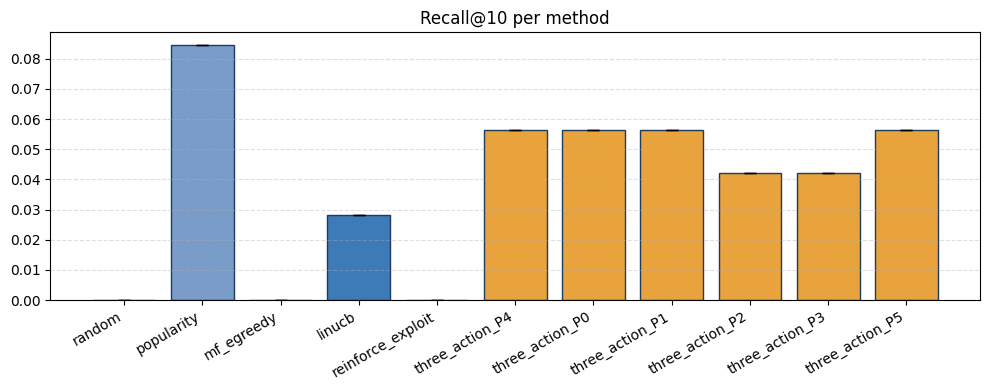

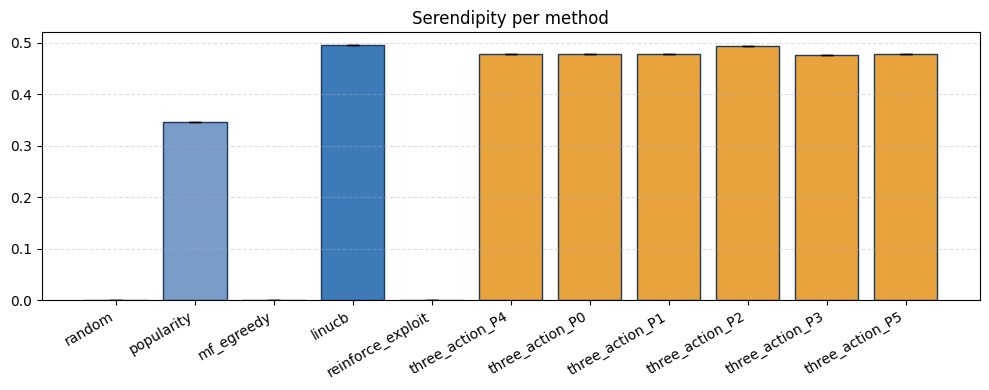

In [ ]:
%matplotlib inline
# visualize モジュールが Agg に切り替えるため、ノートブック表示用に inline へ戻す
import matplotlib.pyplot as plt
import numpy as np

def bar(metric, title):
    methods = list(agg)
    means = [agg[m][f'{metric}_mean'] for m in methods]
    stds = [agg[m][f'{metric}_std'] for m in methods]
    colors = [visualize.PALETTE.get(m.split('_P')[0], '#5A6478') for m in methods]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(np.arange(len(methods)), means, yerr=stds, color=colors, capsize=4, edgecolor='#1F3A5F')
    ax.set_xticks(np.arange(len(methods)))
    ax.set_xticklabels(methods, rotation=30, ha='right')
    ax.set_title(title); ax.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout(); plt.show()

bar('recall', 'Recall@10 per method')
bar('serendipity', 'Serendipity per method')

### 行動配分（P0〜P5）

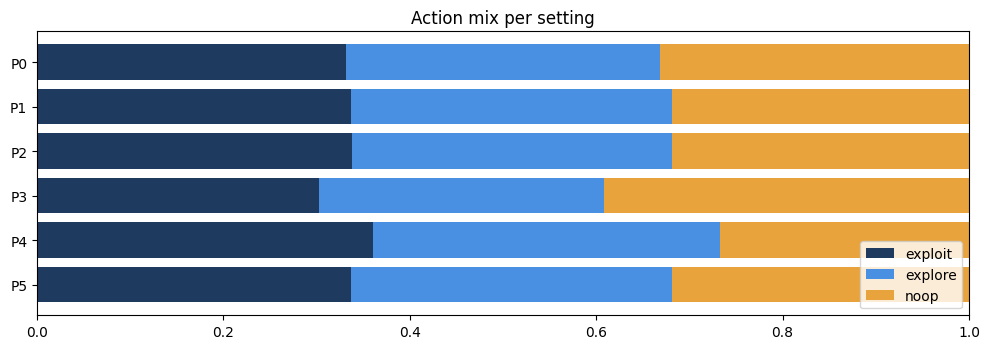

In [ ]:
%matplotlib inline
tags = [s['tag'] for s in sweep]
mix = np.array([[s['action_mix'][a] for a in ('exploit', 'explore', 'noop')] for s in sweep])
fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(len(tags))
for i, (a, c) in enumerate(zip(('exploit', 'explore', 'noop'), ('#1F3A5F', '#4A90E2', '#E8A33D'))):
    ax.barh(tags, mix[:, i], left=left, color=c, label=a); left += mix[:, i]
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.legend(loc='lower right'); ax.set_title('Action mix per setting')
plt.tight_layout(); plt.show()

## 7. OPE 推定値（IPS / SNIPS / 重み二乗平均）

In [ ]:
for s in sweep:
    print(f"[{s['method']}] seed={s['seed']} IPS={s['ope_ips']:.4f} SNIPS={s['ope_snips']:.4f} "
          f"weight²={s['ope_dr_proxy_var']:.4f}")

[three_action_P0] seed=0 IPS=0.5671 SNIPS=0.5671 weight²=1.0000
[three_action_P1] seed=0 IPS=0.4412 SNIPS=0.4412 weight²=1.0000
[three_action_P2] seed=0 IPS=0.6077 SNIPS=0.6077 weight²=1.0000
[three_action_P3] seed=0 IPS=0.1929 SNIPS=0.1929 weight²=1.0000
[three_action_P4] seed=0 IPS=0.3332 SNIPS=0.3332 weight²=1.0000
[three_action_P5] seed=0 IPS=0.4412 SNIPS=0.4412 weight²=1.0000


## 注意と次の一歩
- 小さなサブセット・単一 seed の結果は配線確認用です。傾向を見るときは `N_USERS` と `SEEDS` を増やしてください。
- 実 MovieLens-100k を使う場合は、セクション 3 の `DATA_ROOT` に `ml-100k` フォルダか `ml-100k.zip` のパスを指定します。
- 報酬式は `movierec/proposed.py` の `shaped_reward`、パラメータは `run_experiment.THREE_ACTION_TAGS` で変更できます。